In [1]:

!pip -q install pandas pyarrow scikit-learn matplotlib seaborn openpyxl


In [3]:

import glob
import os

parquet_files = sorted(glob.glob("/content/*.parquet"))

print(f"Total Parquet files: {len(parquet_files)}")
for path in parquet_files:
    print(os.path.basename(path))

assert len(parquet_files) == 8, (
    "Please upload the remaining Parquet files before continuing."
)

print("\nAll 8 files are ready for Round 2!")


Total Parquet files: 8
Benign-Monday-no-metadata.parquet
Botnet-Friday-no-metadata.parquet
Bruteforce-Tuesday-no-metadata.parquet
DDoS-Friday-no-metadata.parquet
DoS-Wednesday-no-metadata.parquet
Infiltration-Thursday-no-metadata.parquet
Portscan-Friday-no-metadata.parquet
WebAttacks-Thursday-no-metadata.parquet

All 8 files are ready for Round 2!


In [4]:

import pandas as pd
import numpy as np
import os

frames = []

for path in parquet_files:
    part = pd.read_parquet(path)

    if len(part) > 12500:
        part = part.sample(n=12500, random_state=42)

    frames.append(part)
    print(os.path.basename(path), ":", len(part), "rows")

df = pd.concat(frames, ignore_index=True)
df.columns = df.columns.str.strip()

df = df.drop_duplicates().copy()
df["Label"] = df["Label"].astype("string").str.strip()
df = df.dropna(subset=["Label"])
df = df[df["Label"] != ""]

# 0 = Normal, 1 = Unusual
normal_labels = {"BENIGN", "NORMAL", "NORMAL TRAFFIC"}
df["target"] = (
    ~df["Label"].str.upper().isin(normal_labels)
).astype(int)

candidate_features = [
    c for c in df.columns if c not in ["Label", "target"]
]

for col in candidate_features:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df[candidate_features] = df[candidate_features].replace(
    [np.inf, -np.inf], np.nan
)

features = [
    c for c in candidate_features
    if df[c].notna().any()
    and df[c].nunique(dropna=True) > 1
]

X = df[features].copy()
X = X.fillna(X.median()).fillna(0)
y = df["target"]

print("\nTotal records:", len(df))
print("Numeric features:", len(features))
print("\nOriginal label distribution:")
print(df["Label"].value_counts())
print("\nTarget distribution:")
print(y.map({0: "Normal", 1: "Unusual"}).value_counts())


Benign-Monday-no-metadata.parquet : 12500 rows
Botnet-Friday-no-metadata.parquet : 12500 rows
Bruteforce-Tuesday-no-metadata.parquet : 12500 rows
DDoS-Friday-no-metadata.parquet : 12500 rows
DoS-Wednesday-no-metadata.parquet : 12500 rows
Infiltration-Thursday-no-metadata.parquet : 12500 rows
Portscan-Friday-no-metadata.parquet : 12500 rows
WebAttacks-Thursday-no-metadata.parquet : 12500 rows

Total records: 99618
Numeric features: 67

Original label distribution:
Label
Benign                        87531
DDoS                           7197
DoS Hulk                       3712
DoS GoldenEye                   220
PortScan                        202
FTP-Patator                     197
Web Attack � Brute Force        116
DoS slowloris                   107
DoS Slowhttptest                101
Bot                              96
SSH-Patator                      81
Web Attack � XSS                 48
Infiltration                      6
Web Attack � Sql Injection        4
Name: count, dtype: In

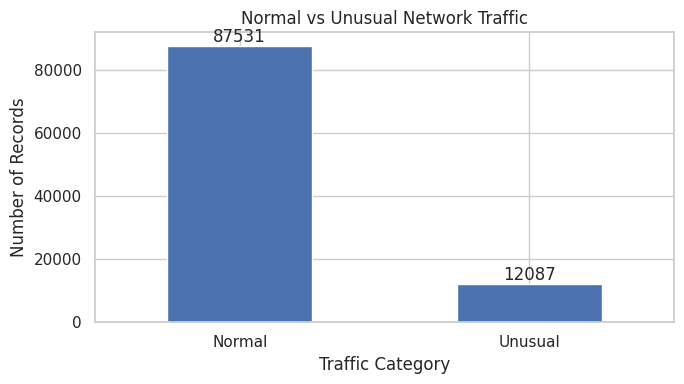

In [5]:

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

counts = y.map({0: "Normal", 1: "Unusual"}).value_counts()
counts = counts.reindex(["Normal", "Unusual"], fill_value=0)

ax = counts.plot(kind="bar", figsize=(7, 4))
ax.set_title("Normal vs Unusual Network Traffic")
ax.set_xlabel("Traffic Category")
ax.set_ylabel("Number of Records")
ax.tick_params(axis="x", rotation=0)

for bars in ax.containers:
    ax.bar_label(bars)

plt.tight_layout()
plt.show()


In [6]:

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, classification_report, confusion_matrix
)

if y.nunique() < 2 or y.value_counts().min() < 2:
    raise ValueError("At least two classes with two records each are required.")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

model = RandomForestClassifier(
    n_estimators=150,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

model.fit(X_train, y_train)
y_pred = model.predict(X_test)

metrics = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision (Unusual)": precision_score(
        y_test, y_pred, zero_division=0
    ),
    "Recall (Unusual)": recall_score(
        y_test, y_pred, zero_division=0
    ),
    "F1 Score (Unusual)": f1_score(
        y_test, y_pred, zero_division=0
    )
}

print("MODEL PERFORMANCE")
for name, score in metrics.items():
    print(f"{name}: {score:.4%}")

print("\nClassification report:")
print(classification_report(
    y_test, y_pred,
    labels=[0, 1],
    target_names=["Normal", "Unusual"],
    zero_division=0
))


MODEL PERFORMANCE
Accuracy: 99.7270%
Precision (Unusual): 99.3320%
Recall (Unusual): 98.4116%
F1 Score (Unusual): 98.8697%

Classification report:
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00     21883
     Unusual       0.99      0.98      0.99      3022

    accuracy                           1.00     24905
   macro avg       1.00      0.99      0.99     24905
weighted avg       1.00      1.00      1.00     24905



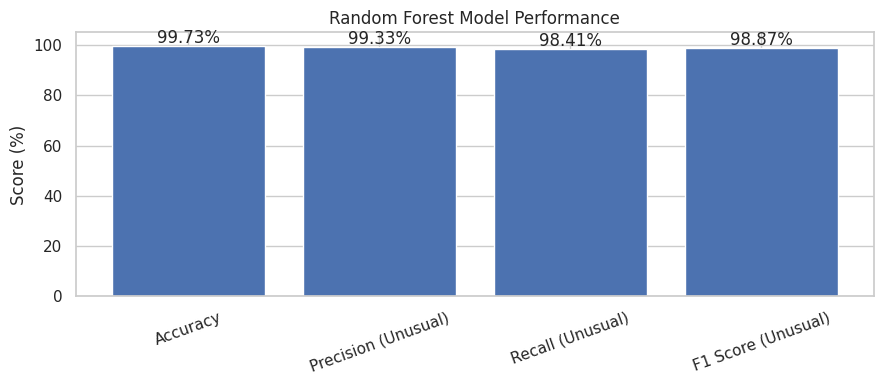

In [7]:

names = list(metrics.keys())
scores = [v * 100 for v in metrics.values()]

fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.bar(names, scores)

ax.set_title("Random Forest Model Performance")
ax.set_ylabel("Score (%)")
ax.set_ylim(0, 105)
ax.tick_params(axis="x", rotation=20)

for bar, score in zip(bars, scores):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{score:.2f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()


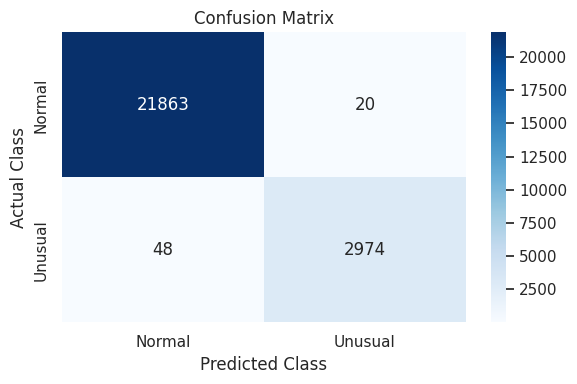

In [8]:

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Normal", "Unusual"],
    yticklabels=["Normal", "Unusual"]
)
plt.title("Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()


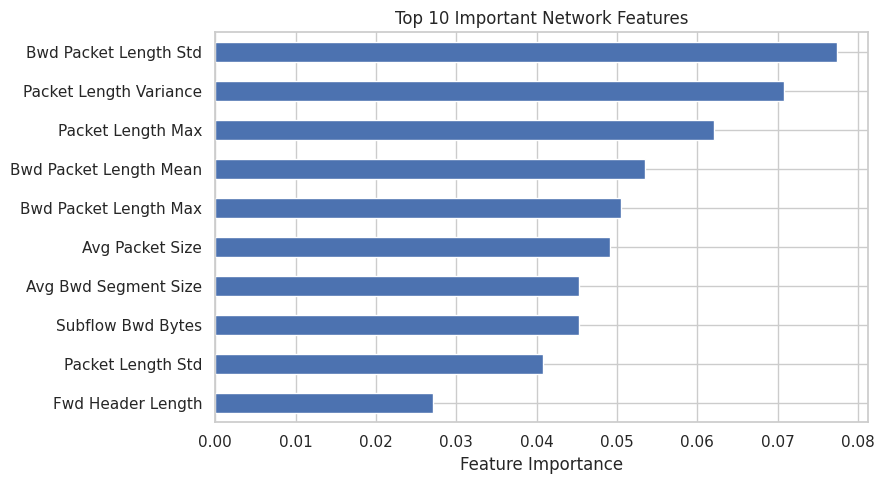

,Importance
Bwd Packet Length Std,0.077373
Packet Length Variance,0.070812
Packet Length Max,0.062107
Bwd Packet Length Mean,0.053518
Bwd Packet Length Max,0.050569
Avg Packet Size,0.049119
Avg Bwd Segment Size,0.045323
Subflow Bwd Bytes,0.045300
Packet Length Std,0.040851
Fwd Header Length,0.027106


In [9]:

importance = pd.Series(
    model.feature_importances_, index=features
).sort_values(ascending=False)

plt.figure(figsize=(9, 5))
importance.head(10).sort_values().plot(kind="barh")
plt.title("Top 10 Important Network Features")
plt.xlabel("Feature Importance")
plt.tight_layout()
plt.show()

display(importance.head(10).to_frame("Importance"))


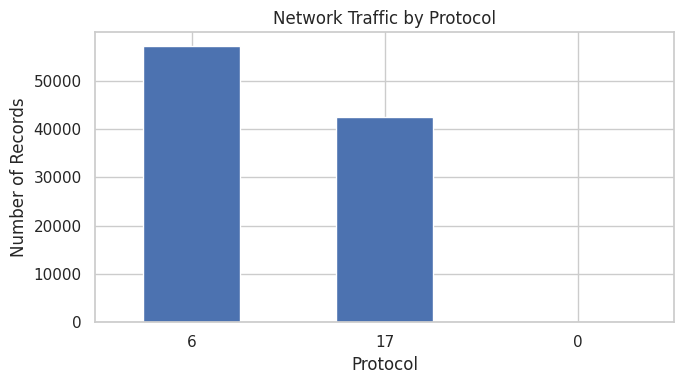

In [10]:

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 4))
df["Protocol"].value_counts().plot(kind="bar")
plt.title("Network Traffic by Protocol")
plt.xlabel("Protocol")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


,Packet Length Mean,Packet Length Max,Packet Length Variance
target,,,
Normal,64.400002,104.0,1.106143e+03
Unusual,833.500000,4380.0,2.706820e+06


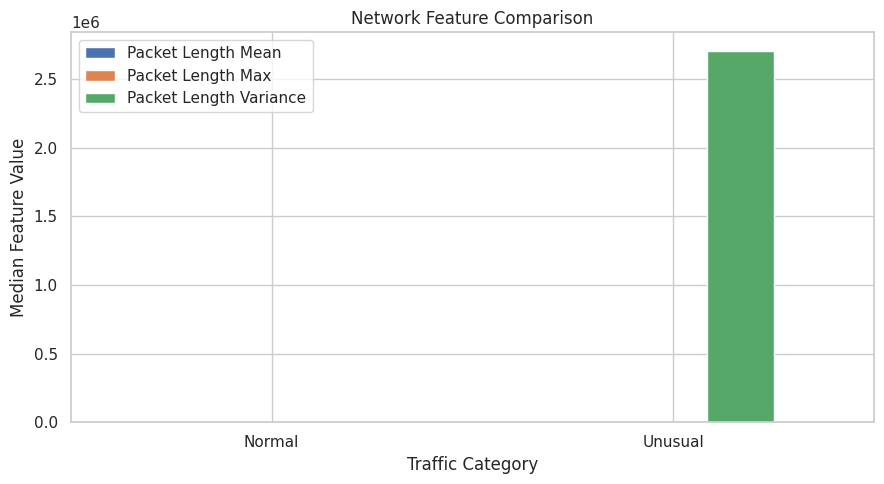

In [11]:

comparison = df.groupby("target")[
    ["Packet Length Mean", "Packet Length Max",
     "Packet Length Variance"]
].median()

comparison.index = comparison.index.map({
    0: "Normal",
    1: "Unusual"
})

display(comparison)

comparison.plot(kind="bar", figsize=(9, 5))
plt.title("Network Feature Comparison")
plt.xlabel("Traffic Category")
plt.ylabel("Median Feature Value")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


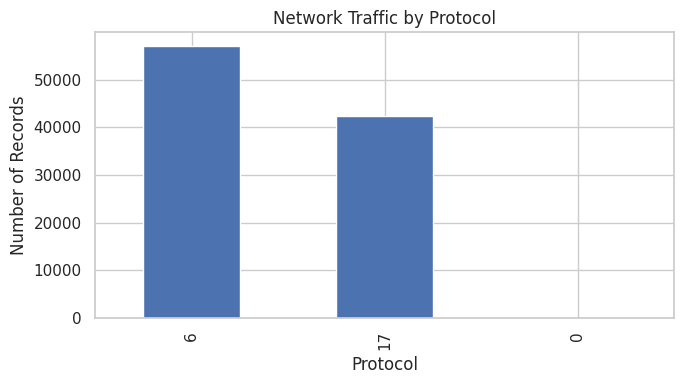

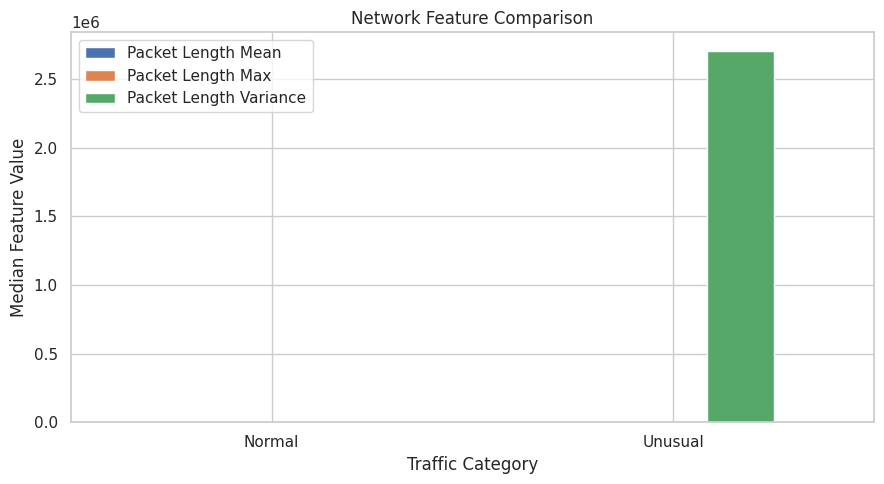

Round 3 graphs saved in: /content/round3_results


In [12]:

import os

round3_dir = "/content/round3_results"
os.makedirs(round3_dir, exist_ok=True)

# Save protocol distribution
fig = plt.figure(figsize=(7, 4))
df["Protocol"].value_counts().plot(kind="bar")
plt.title("Network Traffic by Protocol")
plt.xlabel("Protocol")
plt.ylabel("Number of Records")
plt.tight_layout()
fig.savefig(f"{round3_dir}/protocol_distribution.png", dpi=150)
plt.show()
plt.close(fig)

# Save feature comparison
fig = plt.figure(figsize=(9, 5))
comparison.plot(kind="bar", ax=plt.gca())
plt.title("Network Feature Comparison")
plt.xlabel("Traffic Category")
plt.ylabel("Median Feature Value")
plt.xticks(rotation=0)
plt.tight_layout()
fig.savefig(f"{round3_dir}/feature_comparison.png", dpi=150)
plt.show()
plt.close(fig)

print("Round 3 graphs saved in:", round3_dir)
